In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *


## reading results from simulations

In [2]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_fixed = pd.read_csv("../results/results_vect_paramsfixed_time.csv")
df_new = pd.read_csv('../results/results_vect_ADGT.csv')
df_08_05 = pd.read_csv('../results/results_vect_ADGT_0.8_0.5_more_e.csv')
df_07_02 = pd.read_csv('../results/results_vect_ADGT_0.7_0.2_more_e.csv')
df_08_05_uniform = pd.read_csv('../results/results_vect_uniform_0.8_0.5_more_e.csv')
df_07_02_uniform = pd.read_csv('../results/results_vect_uniform_0.7_0.2_more_e.csv')
df_ACGT = pd.read_csv('../results/results_vect_ACGT_0702.csv')


In [3]:
#excluding lambda > 0.8
df_fixed = df_fixed[df_fixed['lambda']<=0.8]

In [4]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df

# Columns to round
columns_to_round = ['delta', 'e', 'lambda', 'alpha']

# Apply the function to df
# Apply the function to df_fixed
df_fixed = round_columns(df_fixed, columns_to_round, 2)
df = round_columns(df, columns_to_round, 2)
df_new = round_columns(df_new, columns_to_round, 2)
df_08_05 = round_columns(df_08_05, columns_to_round, 2)
df_07_02 = round_columns(df_07_02, columns_to_round, 2)
df_08_05_uniform= round_columns(df_08_05_uniform, columns_to_round, 2)
df_07_02_uniform= round_columns(df_07_02_uniform, columns_to_round, 2)
df_ACGT= round_columns(df_ACGT, columns_to_round, 2)

df_fixed['M'] = df_fixed['M'].round(0)
df_new['M'] = df_new['M'].round(0)


In [5]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

[('delta', 'e'), ('delta', 'lambda'), ('delta', 'alpha'), ('e', 'lambda'), ('e', 'alpha'), ('lambda', 'alpha')]


/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/MultiAgent/../utils.py:732: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


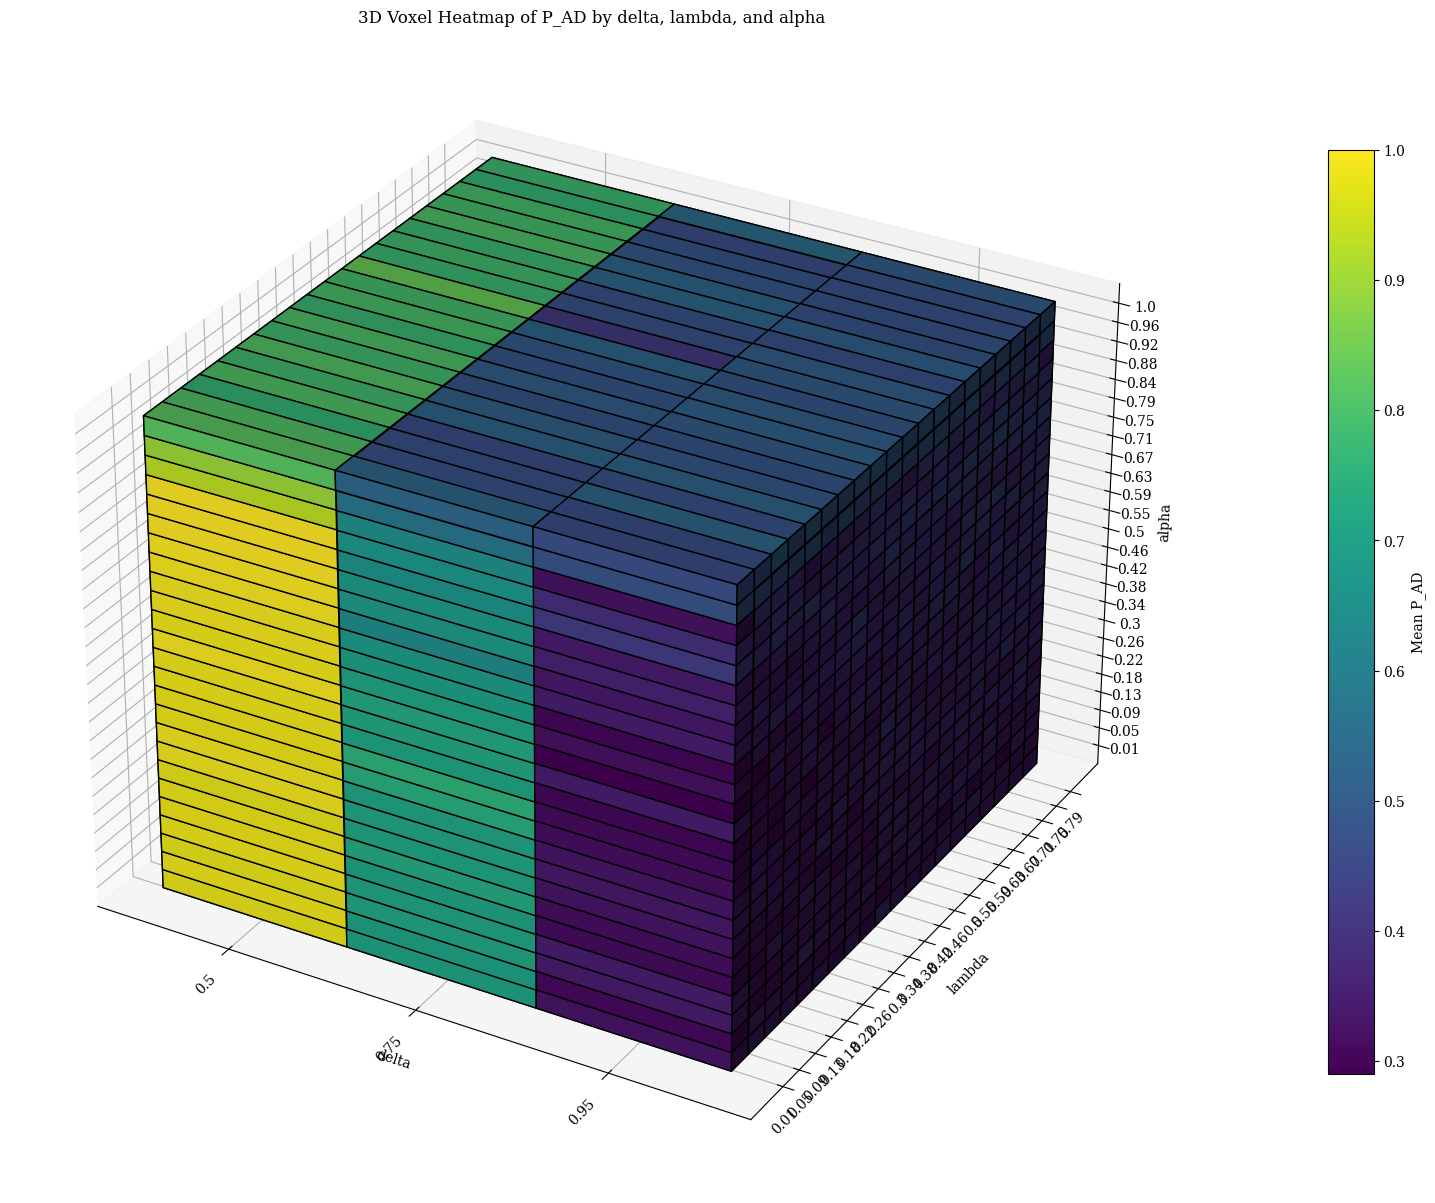

/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/MultiAgent/../utils.py:732: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


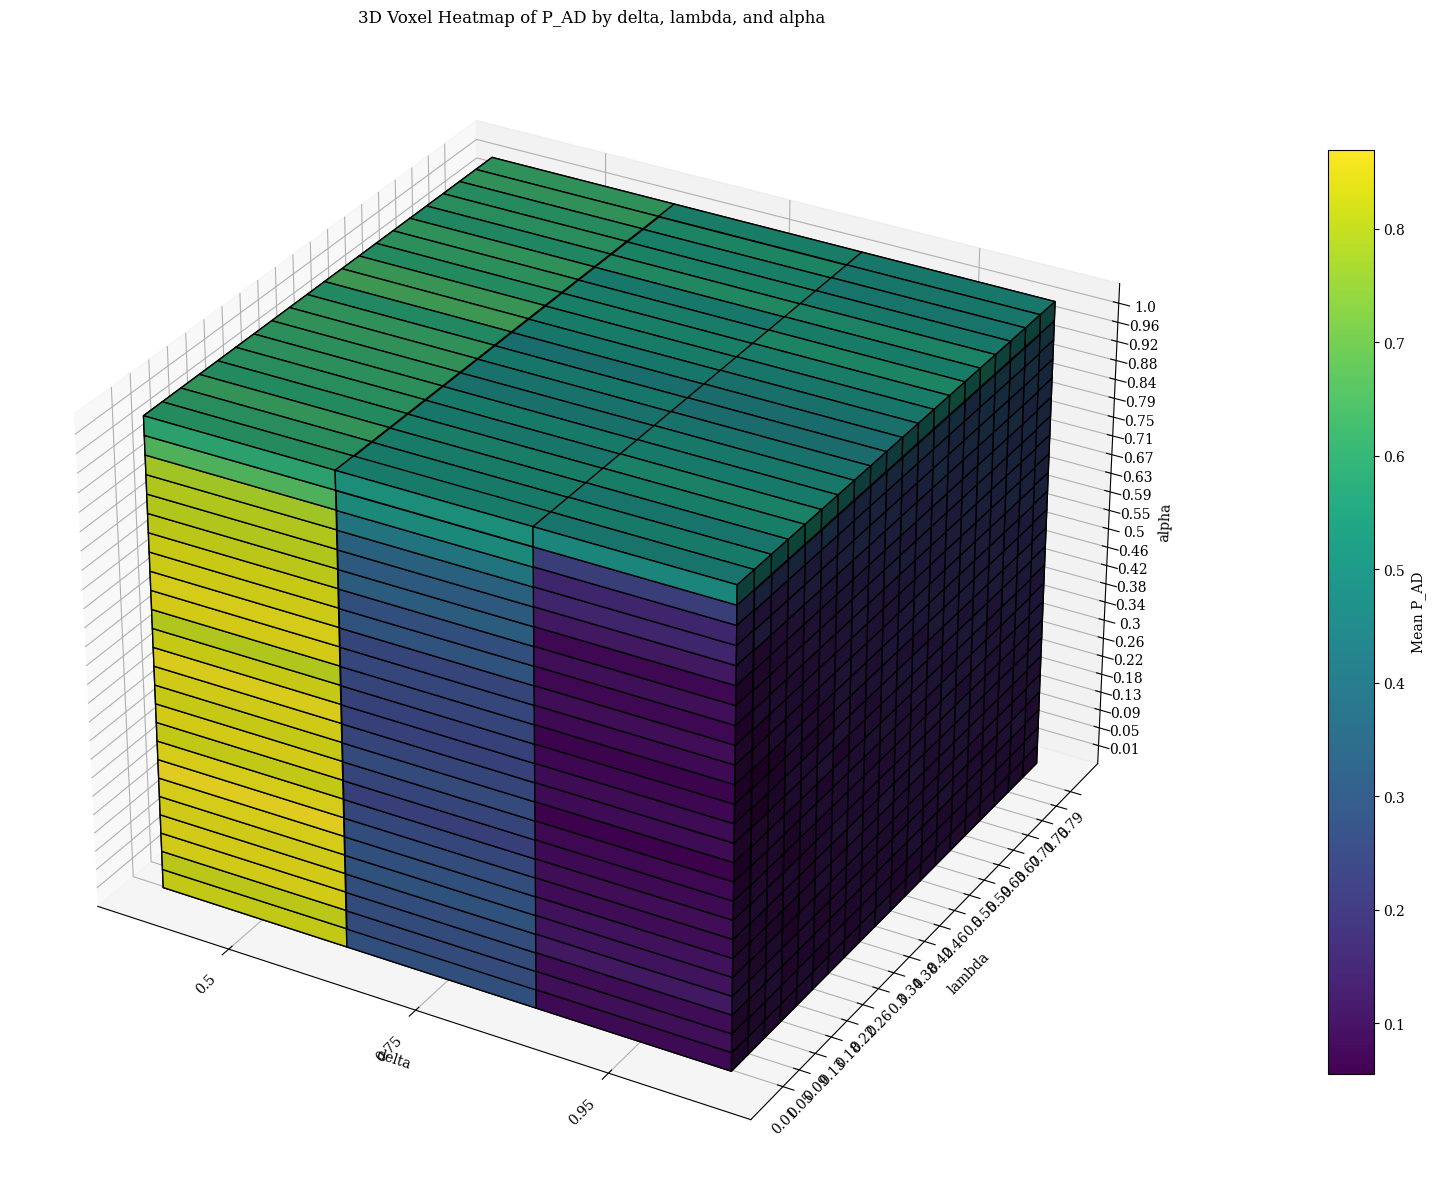

In [6]:
heatmap_3d_voxels(df_08_05, 'delta', 'lambda', 'alpha', value='P_AD')
heatmap_3d_voxels(df_07_02, 'delta', 'lambda', 'alpha', value='P_AD')


In [7]:
interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= False)

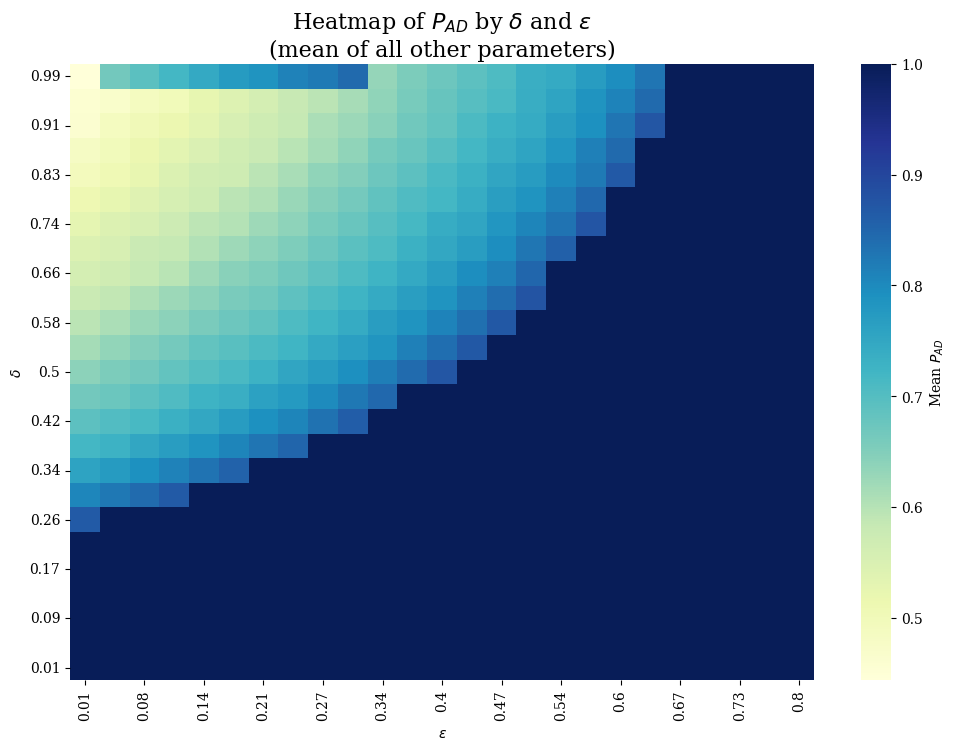

In [8]:
heatmap_mean(df, 'delta', 'e', 'P_AD')

In [9]:
lambdas = np.sort(df_fixed['lambda'].unique())
lambdas

array([0.01, 0.05, 0.09, 0.13, 0.18, 0.22, 0.26, 0.3 , 0.34, 0.38, 0.42,
       0.46, 0.5 , 0.55, 0.59, 0.63, 0.67, 0.71, 0.75, 0.79])

In [10]:
def filter_for_plot(df, na = 5, nl = 8):
    alphas = np.sort(df['alpha'].unique())
    selected = alphas[np.linspace(0, len(alphas) - 1, na).astype(int)]
    lambdas = np.sort(df['lambda'].unique())
    selected_l = lambdas[np.linspace(0, len(lambdas) - 1, nl).astype(int)]
    stric_s = selected_l[:-3]
    df_filtered = df[df['alpha'].isin(selected)]
    df_filtered = df_filtered[df_filtered['lambda'].isin(stric_s)]
    return df_filtered

In [11]:
df_filtered = filter_for_plot(df_07_02, na = 5, nl = 8)
print('alpha values:',df_filtered['alpha'].unique())
print('lambda values:', df_filtered['lambda'].unique())


alpha values: [0.01 0.26 0.5  0.75 1.  ]
lambda values: [0.01 0.09 0.22 0.34 0.42]


In [12]:
df_filtered.M.value_counts()

M
20     375
100    375
500    300
Name: count, dtype: int64

## Uniform Initialization

In [13]:
from basin import *

In [14]:
e, delta = 0.2,0.5
t, r, p, s = 1, 0.7, 0.2, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)

(np.float64(0.5565476190476188), np.float64(0.8690476190476188))

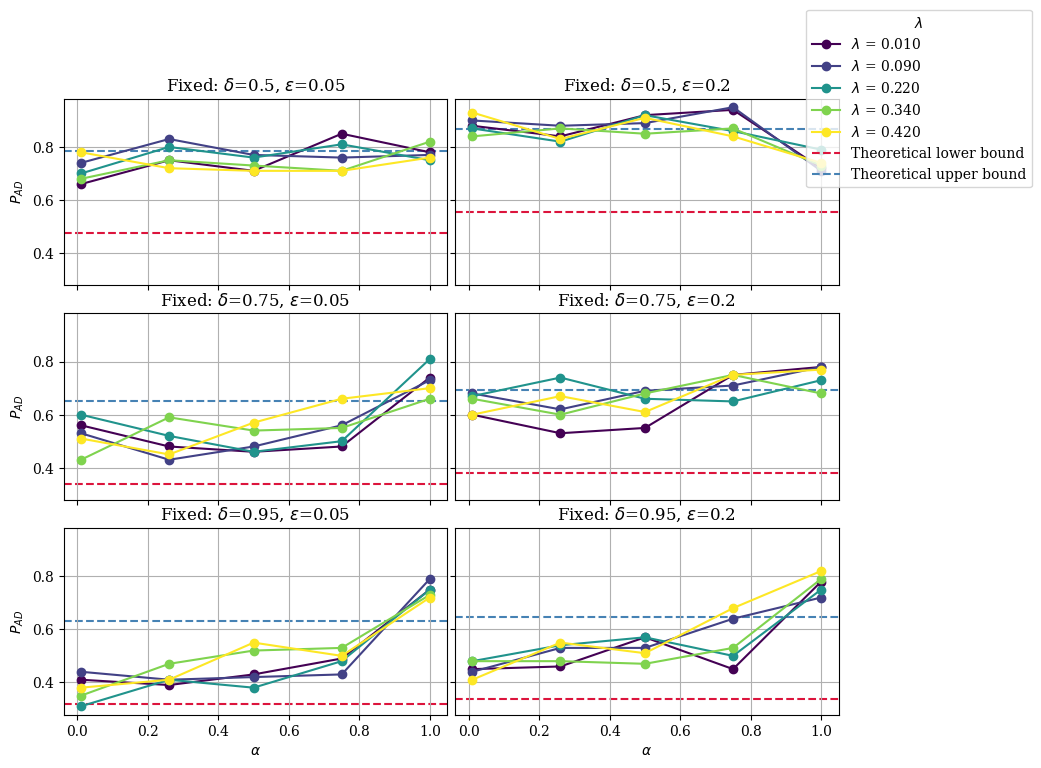

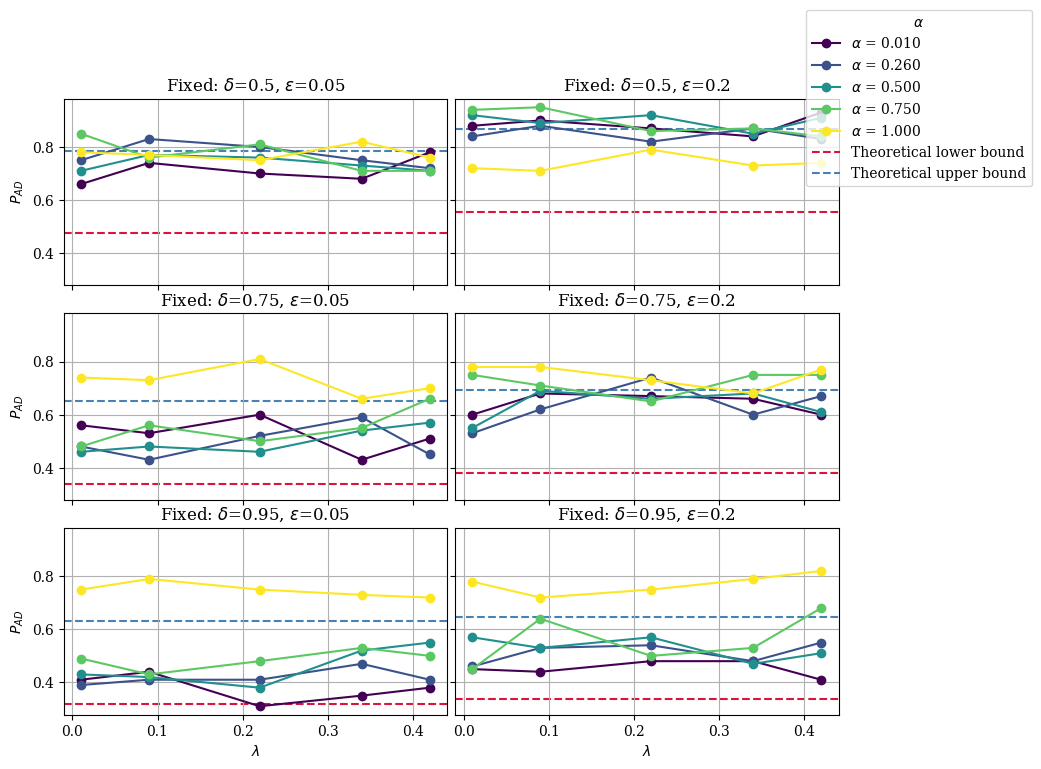

In [15]:
df_07_02_uniform_filtered = filter_for_plot(df_07_02_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.2},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.2},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.2},
]

m=100
y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
from MultiAgent.basin import get_aggregate_bounds
theoretical_bounds = [get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=ps['e'], d=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_07_02_uniform_filtered, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds)
plot_multiple_panels(df_07_02_uniform_filtered, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds)

In [16]:
e, delta = 0.05,0.95
t, r, p, s = 1, 0.8, 0.5, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)

(np.float64(0.3371250000000001), np.float64(0.6496250000000001))

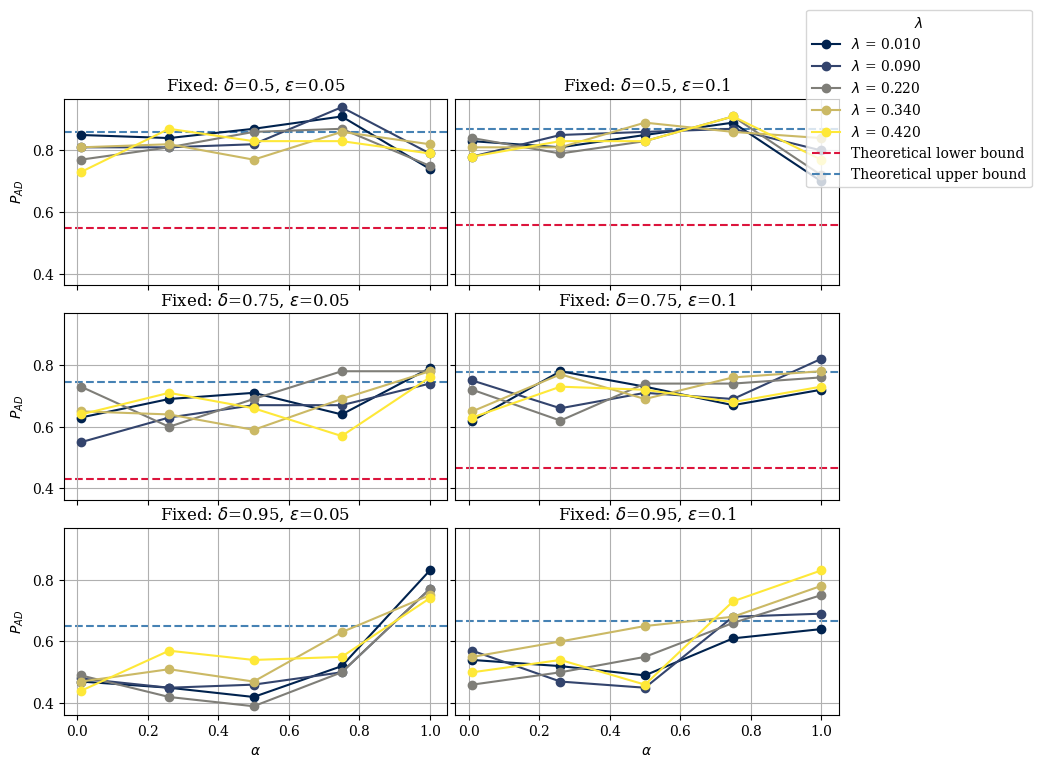

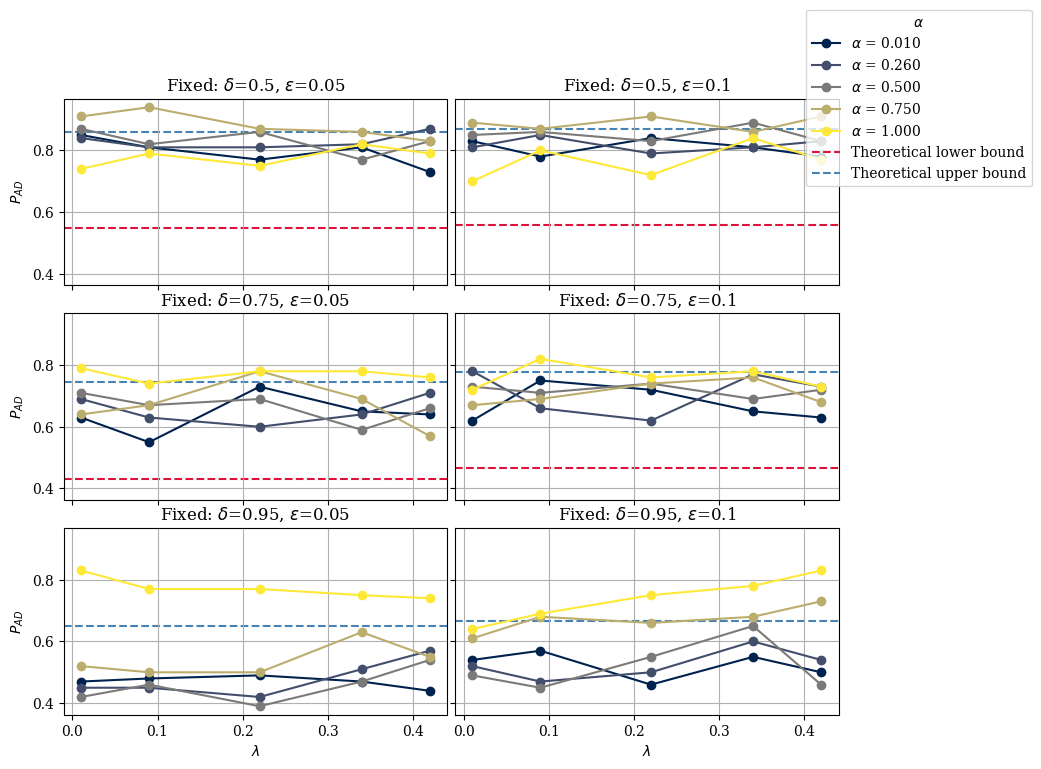

In [18]:
df_08_05_uniform_filtered = filter_for_plot(df_08_05_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_AD'

t, r, p, s = 1, 0.8, 0.5, 0
from MultiAgent.basin import get_aggregate_bounds
theoretical_bounds = [get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=ps['e'], d=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_08_05_uniform_filtered, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=100, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds)
plot_multiple_panels(df_08_05_uniform_filtered, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=100, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds)

## ADGT plots

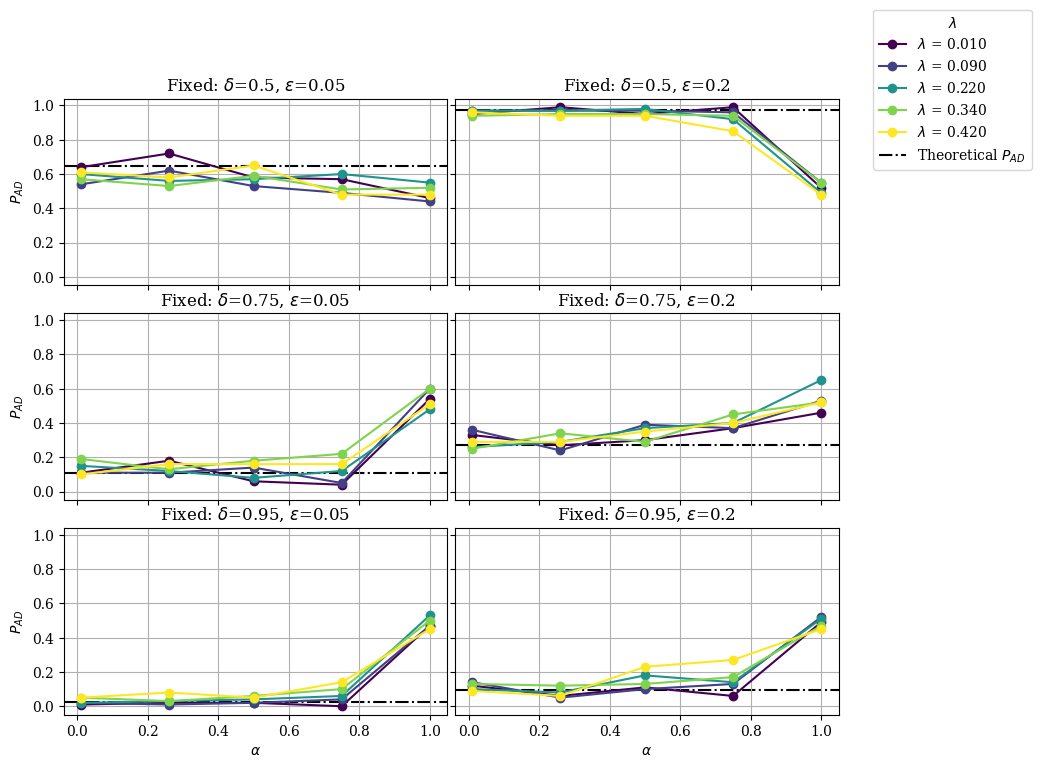

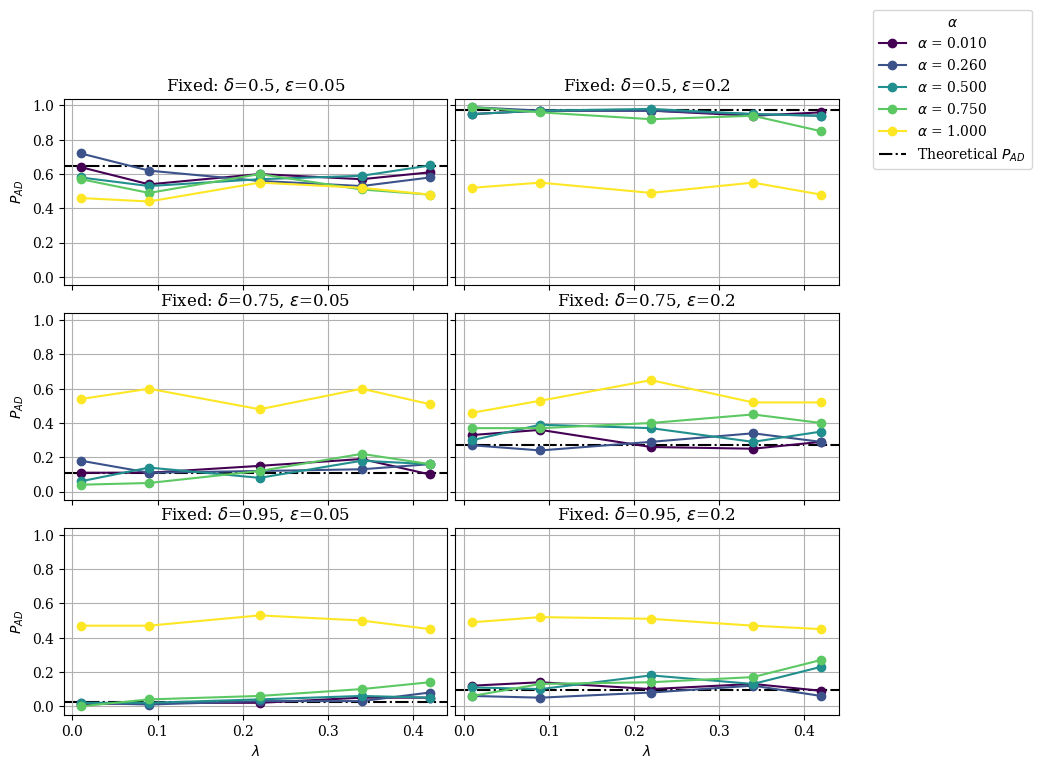

In [ ]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.2},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.2},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.2},
]

m=100
y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
from MultiAgent.basin import theoretical_P_AD_from_ADGT

theoretical_per_panel = [theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
theoretical_per_panel_c_s = [theoretical_P_AD_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
#TODO:color-blind cmap.
plot_multiple_panels(df_filtered, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c_s)
plot_multiple_panels(df_filtered, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c_s)

In [ ]:
df_filtered_s = filter_for_plot(df_08_05, na = 5, nl = 8)

In [ ]:
df_filtered_s.e.unique()

array([0.05, 0.1 , 0.15, 0.2 , 0.3 ])

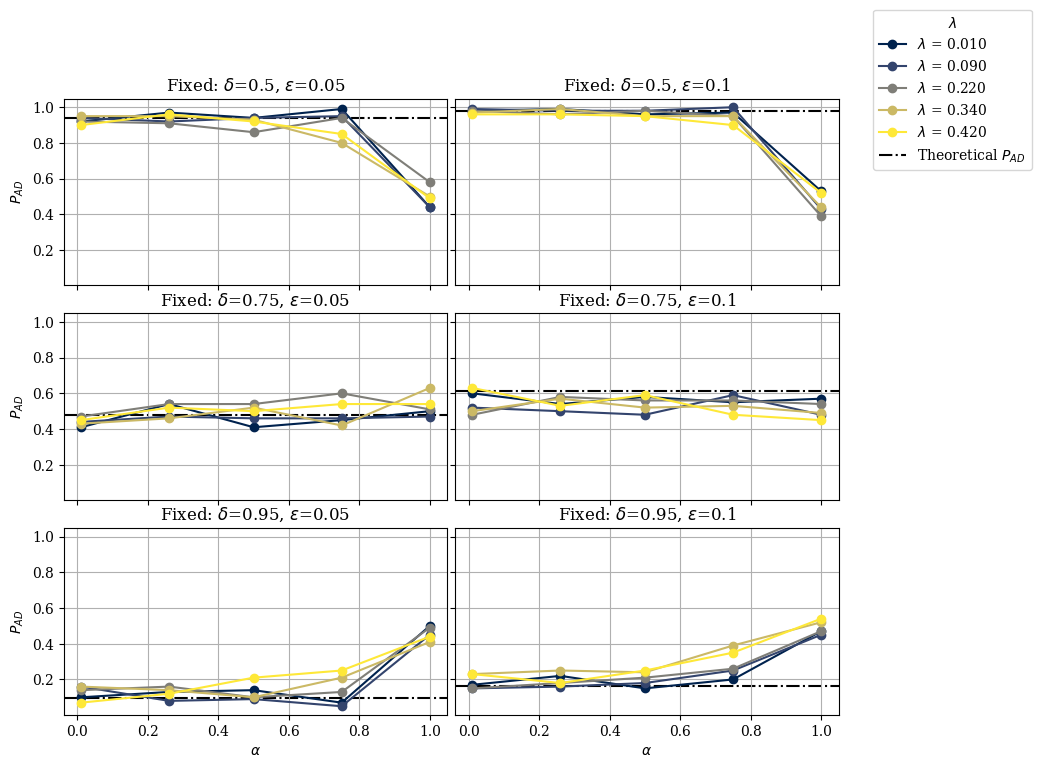

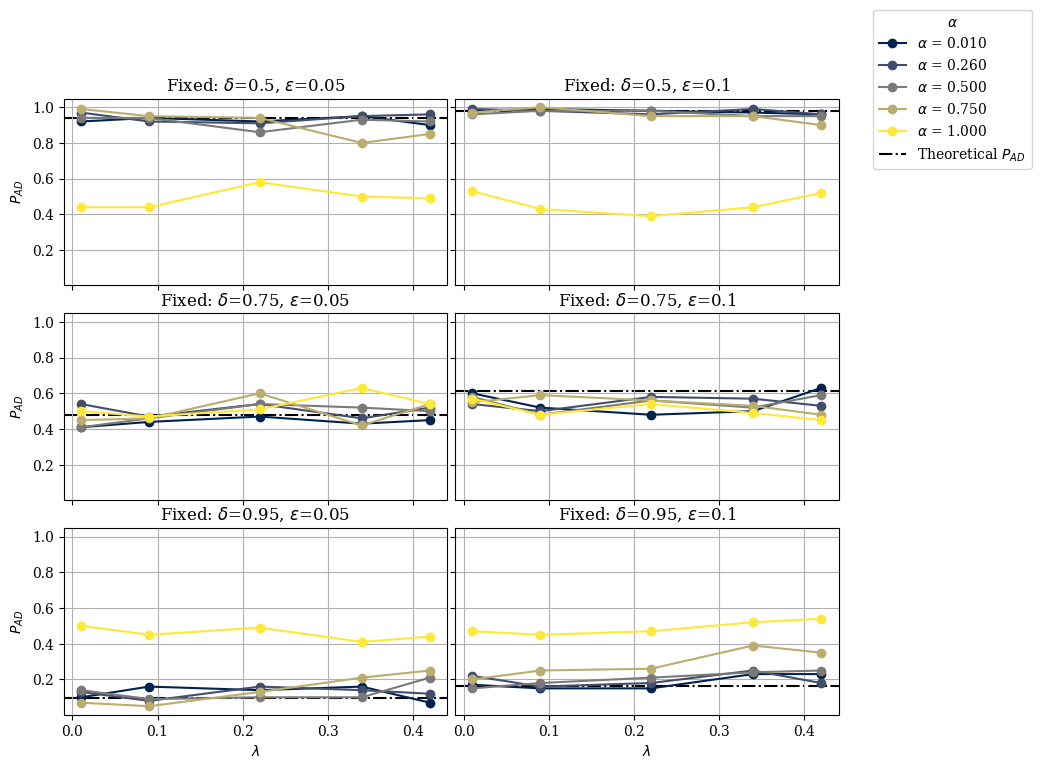

In [ ]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

m=100
y = 'P_AD'
from MultiAgent.basin import theoretical_P_AD_from_ADGT
theoretical_per_panel_c = [theoretical_P_AD_from_ADGT(t=1, r=0.8, p=0.5, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_filtered_s, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=m, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c)
plot_multiple_panels(df_filtered_s, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=m, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c)

## ACGT Plots

In [ ]:
df_filtered = filter_for_plot(df_ACGT, na = 5, nl = 8)

In [ ]:
df_ACGT['P_GT'].mean()

np.float64(0.5780392259414227)

In [ ]:
df_ACGT['P_AD'].mean()

np.float64(0.4219607740585774)

In [ ]:
def theoretical_P_AD_from_ACGT(t=1, r=0.7, p=0.2, s=0, epsilon=0.1, d=0.6,
                                state_idx=0, delta=None, e=None):
    """
    Theoretical P(AD) from the (AC, GT) initialization.
    From Proposition (general basin), the symmetric bifurcation case:
    P(GT,GT | GT,AC) = 0.5 * (1 + pi_GTGT)
    Therefore:
    P(AD,AD | GT,AC) = 1 - P(GT,GT | GT,AC) = 1 - 0.5 * (1 + pi_GTGT)
                     = 0.5 * (1 - pi_GTGT)
    """
    if delta is not None:
        d = delta
    if e is not None:
        epsilon = e

    Q_AD = QvaluesADvsAD(t, r, p, s, epsilon, d)[state_idx]
    Q_GT = QvaluesGTvsGT(t, r, p, s, epsilon, d)[state_idx]

    abs_dx = abs(Q_AD[0] - Q_AD[1])
    abs_dy = abs(Q_GT[0] - Q_GT[1])

    pi_small = 0.5 * min(abs_dx, abs_dy) / max(abs_dx, abs_dy) if max(abs_dx, abs_dy) > 0 else 0.5
    pi_GTGT = (1.0 - pi_small) if abs_dx < abs_dy else (pi_small if abs_dx > abs_dy else 0.5)

    P_AD = 0.5 * (1 - pi_GTGT)
    return float(P_AD)

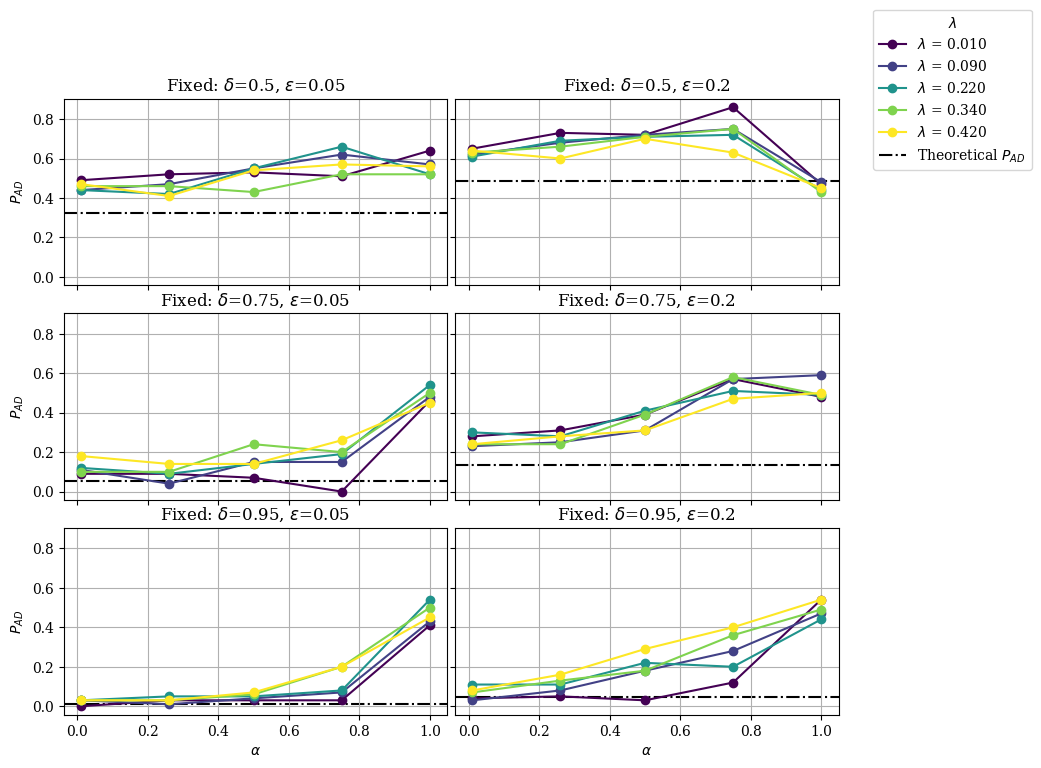

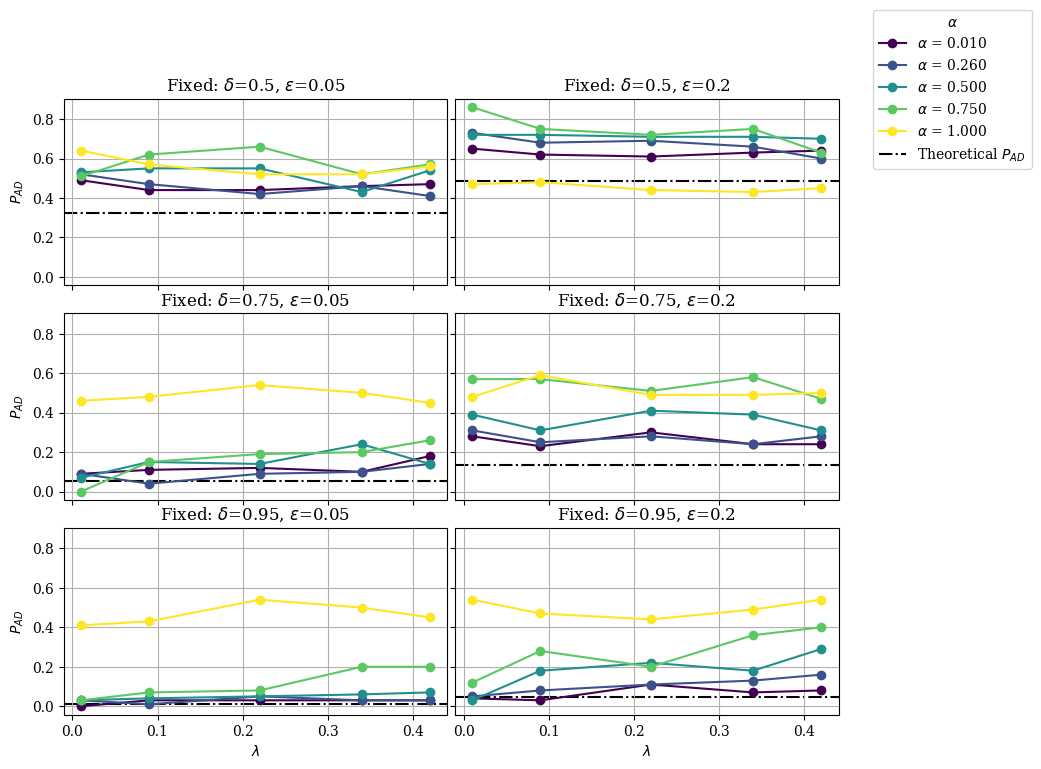

In [ ]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.2},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.2},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.2},
]

m=100
y = 'P_AD'

t, r, p, s = 1, 0.7, 0.2, 0
theoretical_per_panel_acgt = [theoretical_P_AD_from_ACGT(t=1, r=0.7, p=0.2, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]
plot_multiple_panels(df_filtered, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_acgt)
plot_multiple_panels(df_filtered, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=100, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_acgt)